# 01 · MIND-small data audit

A first look at the **news** domain before any graph or model work. We load the raw
`behaviors.tsv` and `news.tsv` for the train and dev splits and answer nine questions
about size, time, clicks, users, articles, entities, cold start and overlap.

**Vocabulary used throughout**

- **Impression**: one page view where a user was shown a list of articles (the *candidates*). Each candidate is labelled clicked (1) or not (0).
- **History**: the articles a user clicked *before* the split's time window. MIND stores it as a fixed snapshot per user, not as a log of clicks inside the window.
- **Candidate row**: one (impression, article) pair, which is the unit a ranking model scores.

Loaders live in `src/recsys/data/mind.py`, so this notebook only contains analysis.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from recsys.data.mind import explode_impressions, load_behaviors, load_news
from recsys.paths import FIGURES_DIR, mind_split_dir

SPLITS = ["train", "dev"]

# --- Chart style: light surface, recessive axes/grid, one fixed colour per split ---
SPLIT_COLORS = {"train": "#2a78d6", "dev": "#eb6834"}  # blue, orange
INK, INK_SECONDARY, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_SECONDARY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.options.display.float_format = "{:,.3f}".format

In [2]:
# Load both splits. Behaviors get parsed timestamps and list columns
# (history / candidates / labels); news gets lists of Wikidata IDs per article.
behaviors = {s: load_behaviors(s) for s in SPLITS}
news = {s: load_news(s) for s in SPLITS}

# Long format: one row per (impression, candidate article, clicked).
candidates = {s: explode_impressions(behaviors[s]) for s in SPLITS}

behaviors["train"].head(3)

,impression_id,user_id,time,history,candidates,labels
0,1,U13740,2019-11-11 09:05:58,"[N55189, N42782, N34694, N45794, N18445, N6330...","[N55689, N35729]","[1, 0]"
1,2,U91836,2019-11-12 18:11:30,"[N31739, N6072, N63045, N23979, N35656, N43353...","[N20678, N39317, N58114, N20495, N42977, N2240...","[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0]"
2,3,U73700,2019-11-14 07:01:48,"[N10732, N25792, N7563, N21087, N41087, N5445,...","[N50014, N23877, N35389, N49712, N16844, N5968...","[0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."


## 1. Row counts

"Unique news (news.tsv)" counts every article in the split's catalogue. "Unique news referenced"
counts only the articles that actually appear in a history or an impression.

In [3]:
def referenced_news(b: pd.DataFrame) -> set[str]:
    # Every news ID that shows up in a history or as an impression candidate.
    return set(b["history"].explode().dropna()) | set(b["candidates"].explode())

counts = pd.DataFrame({
    s: {
        "impressions": len(behaviors[s]),
        "unique users": behaviors[s]["user_id"].nunique(),
        "unique news (news.tsv)": news[s]["news_id"].nunique(),
        "unique news referenced": len(referenced_news(behaviors[s])),
        "candidate rows": len(candidates[s]),
    }
    for s in SPLITS
})
all_news_ids = set(news["train"]["news_id"]) | set(news["dev"]["news_id"])
shared_news_ids = set(news["train"]["news_id"]) & set(news["dev"]["news_id"])
print(f"Articles across both splits: {len(all_news_ids):,} ({len(shared_news_ids):,} in both catalogues)")
counts.style.format("{:,}")

Articles across both splits: 65,238 (28,460 in both catalogues)


,train,dev
impressions,"156,965","73,152"
unique users,"50,000","50,000"
unique news (news.tsv),"51,282","42,416"
unique news referenced,"51,282","42,416"
candidate rows,"5,843,444","2,740,998"


**Interpretation:** Train has about 157k impressions and dev about 73k, and each split has exactly 50,000 users (MIND-small samples them that way). Each split's news.tsv contains exactly the articles that split references, no more. Together they cover about 65k distinct articles, a graph you can hold in memory on a laptop.

## 2. Time span

In [4]:
span = pd.DataFrame({
    s: {
        "first impression": behaviors[s]["time"].min(),
        "last impression": behaviors[s]["time"].max(),
        "calendar days": behaviors[s]["time"].dt.date.nunique(),
    }
    for s in SPLITS
})
display(span)

# Impressions per calendar day, to spot weekday/weekend effects.
per_day = pd.concat(
    {s: behaviors[s]["time"].dt.date.value_counts().sort_index() for s in SPLITS}, axis=1
).fillna(0).astype(int)
per_day.index = pd.to_datetime(per_day.index).strftime("%a %d %b")
per_day

,train,dev
first impression,2019-11-09 00:00:19,2019-11-15 00:00:01
last impression,2019-11-14 23:59:13,2019-11-15 23:58:03
calendar days,6,1


,train,dev
time,,
Sat 09 Nov,13570,0
Sun 10 Nov,15048,0
Mon 11 Nov,32799,0
Tue 12 Nov,33654,0
Wed 13 Nov,31624,0
Thu 14 Nov,30270,0
Fri 15 Nov,0,73152


**Interpretation:** Train covers six days (Sat 9 Nov to Thu 14 Nov 2019) and dev is the single next day (Fri 15 Nov), so the split is strictly by time and dev amounts to "predict tomorrow". The weekend days in train have about half the traffic of weekdays.

## 3. Click-through rate

In [5]:
ctr = pd.DataFrame({
    s: {
        "candidate rows": len(candidates[s]),
        "clicks": int(candidates[s]["clicked"].sum()),
        "CTR": candidates[s]["clicked"].mean(),
        "negatives per positive": (1 - candidates[s]["clicked"].mean()) / candidates[s]["clicked"].mean(),
    }
    for s in SPLITS
}).T
display(ctr.style.format({"candidate rows": "{:,.0f}", "clicks": "{:,.0f}", "CTR": "{:.2%}", "negatives per positive": "{:.1f}"}))

# Clicks per impression: does every impression contain at least one click?
clicks_per_imp = pd.DataFrame({s: behaviors[s]["labels"].map(sum).describe() for s in SPLITS})
clicks_per_imp

,candidate rows,clicks,CTR,negatives per positive
train,"5,843,444","236,344",4.04%,23.7
dev,"2,740,998","111,383",4.06%,23.6


,train,dev
count,"156,965.000","73,152.000"
mean,1.506,1.523
std,1.153,1.138
min,1.000,1.000
25%,1.000,1.000
50%,1.000,1.000
75%,2.000,2.000
max,35.000,24.000


**Interpretation:** Only about 4% of candidates are clicked (roughly 23 non-clicks per click). Every impression contains at least one click (min = 1), usually exactly one, so per-impression ranking metrics (AUC, MRR, nDCG) are always defined.

## 4. User history length

The history is a fixed snapshot per user within a split, so we first check that it is constant across that user's impressions and then measure it once per user.

In [6]:
def history_length_per_user(b: pd.DataFrame) -> pd.Series:
    lengths = b.assign(n=b["history"].map(len)).groupby("user_id")["n"]
    # Sanity check: a user's history should not change across their impressions.
    assert (lengths.nunique() == 1).all(), "history varies within a user"
    return lengths.first()

hist_len = {s: history_length_per_user(behaviors[s]) for s in SPLITS}
pd.DataFrame({
    s: {
        "users": len(h),
        "median": h.median(),
        "p90": h.quantile(0.9),
        "max": h.max(),
        "share empty": (h == 0).mean(),
    }
    for s, h in hist_len.items()
}).T.style.format({"users": "{:,.0f}", "median": "{:.0f}", "p90": "{:.0f}", "max": "{:.0f}", "share empty": "{:.2%}"})

,users,median,p90,max,share empty
train,"50,000",11,42,558,1.78%
dev,"50,000",15,60,444,2.81%


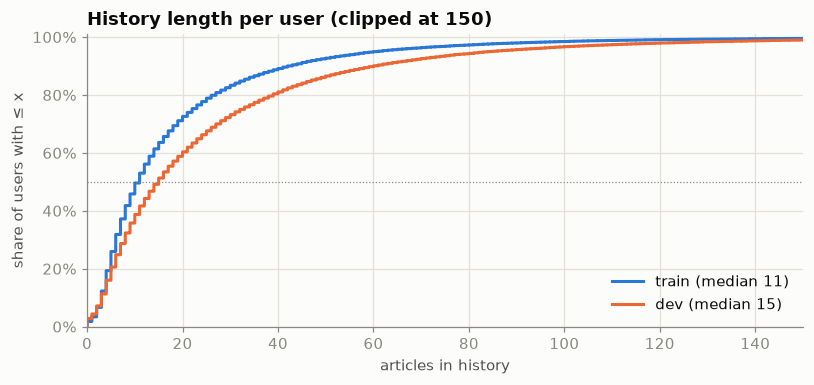

In [7]:
def plot_ecdf(series_by_split: dict, title: str, xlabel: str, ylabel: str, xmax: int, filename: str):
    # Empirical CDF: share of units (y) with a value <= x. One line per split.
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    for s, values in series_by_split.items():
        v = values.sort_values().to_numpy()
        y = (pd.RangeIndex(1, len(v) + 1) / len(v)).to_numpy()
        ax.step(v, y, where="post", lw=2, color=SPLIT_COLORS[s], label=f"{s} (median {values.median():.0f})")
    ax.axhline(0.5, color=MUTED, lw=0.8, ls=":")  # where each line crosses this = its median
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set(xlim=(0, xmax), ylim=(0, 1.01), xlabel=xlabel, ylabel=ylabel)
    ax.set_title(title)
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename)
    plt.show()

plot_ecdf(hist_len, "History length per user (clipped at 150)", "articles in history", "share of users with ≤ x", 150,
          "01_history_length_ecdf.png")

**Interpretation:** A typical user has clicked a dozen or so articles before (median 11 in train, 15 in dev), with a long tail (p90 of 42 to 60, max over 500). Only 2 to 3% of users have an empty history, so almost every user can be described by what they read.

## 5. Candidates per impression

,train,dev
median,24,23
p90,91,92
min,2,2
max,299,295


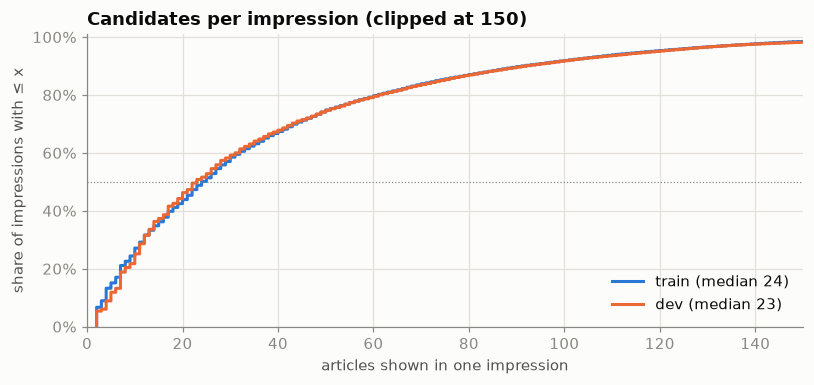

In [8]:
n_candidates = {s: behaviors[s]["candidates"].map(len) for s in SPLITS}
display(pd.DataFrame({
    s: {"median": c.median(), "p90": c.quantile(0.9), "min": c.min(), "max": c.max()}
    for s, c in n_candidates.items()
}).style.format("{:.0f}"))

plot_ecdf(n_candidates, "Candidates per impression (clipped at 150)", "articles shown in one impression", "share of impressions with ≤ x", 150,
          "01_candidates_per_impression_ecdf.png")

**Interpretation:** Impressions usually show around 23 to 24 articles, but the range runs from 2 to nearly 300. Ranking difficulty therefore varies a lot from one impression to the next, so metrics should be averaged per impression, and a cutoff like nDCG@10 means very different things for a 5-item list and a 200-item list.

## 6. Category and subcategory distributions

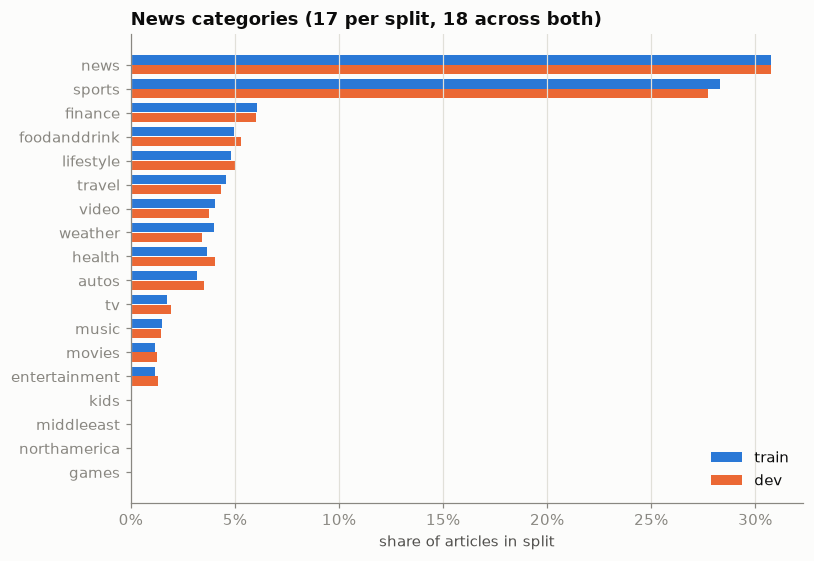

category,news,sports,finance,foodanddrink,lifestyle,travel,video,weather,health,autos,tv,music,movies,entertainment,kids,middleeast,northamerica,games
train,15774,14510,3107,2551,2479,2350,2068,2048,1885,1639,889,769,606,587,17,2,1,0
dev,13043,11760,2563,2248,2132,1845,1600,1462,1715,1490,822,625,538,559,11,2,0,1


In [9]:
cat_share = pd.concat(
    {s: news[s]["category"].value_counts(normalize=True) for s in SPLITS}, axis=1
).fillna(0).sort_values("train")
cat_counts = pd.concat({s: news[s]["category"].value_counts() for s in SPLITS}, axis=1).fillna(0).astype(int)

# Grouped horizontal bars: train and dev share of articles per category.
fig, ax = plt.subplots(figsize=(7.5, 5.2))
bar_h, gap = 0.38, 0.02
y = range(len(cat_share))
for i, s in enumerate(SPLITS):
    offset = (0.5 - i) * (bar_h + gap)  # train above dev, matching the legend
    ax.barh([p + offset for p in y], cat_share[s], height=bar_h, color=SPLIT_COLORS[s], label=s)
ax.set_yticks(list(y), cat_share.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("share of articles in split")
ax.set_title(f"News categories (17 per split, {len(cat_share)} across both)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_category_share.png")
plt.show()

cat_counts.sort_values("train", ascending=False).T

In [10]:
# Subcategories: too many for a chart, so show the count, the concentration and the top 15.
for s in SPLITS:
    sub = news[s]["subcategory"].value_counts()
    print(f"{s}: {len(sub)} subcategories | top 15 cover {sub.head(15).sum() / sub.sum():.0%} of articles | "
          f"{(sub < 10).sum()} have fewer than 10 articles")

(news["train"].groupby(["category", "subcategory"]).size()
    .sort_values(ascending=False).head(15).rename("train articles").reset_index())

train: 264 subcategories | top 15 cover 63% of articles | 112 have fewer than 10 articles
dev: 257 subcategories | top 15 cover 62% of articles | 109 have fewer than 10 articles


,category,subcategory,train articles
0,news,newsus,6564
1,sports,football_nfl,5420
2,news,newspolitics,2826
3,news,newscrime,2254
4,weather,weathertopstories,2047
5,news,newsworld,1720
6,sports,football_ncaa,1665
7,sports,baseball_mlb,1661
8,sports,basketball_nba,1555
9,news,newsscienceandtechnology,1210


**Interpretation:** Each split has 17 categories (`northamerica` appears only in train and `games` only in dev, with one article each), but `news` and `sports` alone make up about 59% of articles, and a handful (`kids`, `middleeast`, `games`) are almost empty. Train and dev have nearly identical mixes. The roughly 260 subcategories have a long tail, with many containing only a few articles.

## 7. Entity coverage

Each article has Wikidata entities linked in its title and/or abstract. We measure the share of articles with at least one entity, the number of distinct Wikidata IDs, and how many of those IDs have a pre-trained vector in the `entity_embedding.vec` files that ship with MIND.

In [11]:
def entity_ids(df: pd.DataFrame) -> set[str]:
    return set(df["title_entity_ids"].explode().dropna()) | set(df["abstract_entity_ids"].explode().dropna())

def coverage_stats(df: pd.DataFrame) -> dict:
    has_title = df["title_entity_ids"].map(len) > 0
    has_abstract = df["abstract_entity_ids"].map(len) > 0
    return {
        "articles": len(df),
        "share with title entity": has_title.mean(),
        "share with abstract entity": has_abstract.mean(),
        "share with any entity": (has_title | has_abstract).mean(),
        "unique Wikidata IDs": len(entity_ids(df)),
    }

all_news = pd.concat(news.values()).drop_duplicates("news_id")
display(pd.DataFrame({**{s: coverage_stats(news[s]) for s in SPLITS}, "both (deduplicated)": coverage_stats(all_news)})
        .T.style.format({"articles": "{:,.0f}", "unique Wikidata IDs": "{:,.0f}",
                         "share with title entity": "{:.1%}", "share with abstract entity": "{:.1%}",
                         "share with any entity": "{:.1%}"}))

# Which entity IDs have a pre-trained TransE vector shipped with MIND?
embedded_ids = set()
for s in SPLITS:
    with open(mind_split_dir(s) / "entity_embedding.vec") as f:
        embedded_ids |= {line.split("\t", 1)[0] for line in f}
all_entity_ids = entity_ids(all_news)
print(f"Entity IDs with a pre-trained vector: {len(all_entity_ids & embedded_ids):,} / {len(all_entity_ids):,} "
      f"({len(all_entity_ids & embedded_ids) / len(all_entity_ids):.1%})")

,articles,share with title entity,share with abstract entity,share with any entity,unique Wikidata IDs
train,"51,282",73.0%,73.0%,86.7%,"27,761"
dev,"42,416",73.4%,72.6%,86.6%,"23,586"
both (deduplicated),"65,238",73.8%,73.8%,87.5%,"32,472"


Entity IDs with a pre-trained vector: 31,451 / 32,472 (96.9%)


**Interpretation:** About 87% of articles mention at least one Wikidata entity (73% in the title alone), and there are about 32k distinct entities, about 97% of which already have a pre-trained vector. Entities are dense enough to act as a real bridge between articles in the graph.

## 8. Cold start: dev candidates never seen in train

An article counts as **seen in train** if it appears in any train history or train impression. We report the share of *unique* dev candidate articles that are unseen, plus the same share weighted by candidate rows and by clicks, because those weightings are what offline metrics actually feel.

In [12]:
train_seen = referenced_news(behaviors["train"])
dev_cand = candidates["dev"].assign(cold=lambda d: ~d["news_id"].isin(train_seen))

unique_dev_cands = dev_cand["news_id"].drop_duplicates()
cold_unique = ~unique_dev_cands.isin(train_seen)

pd.Series({
    "unique dev candidate articles": len(unique_dev_cands),
    "share unseen in train (unique articles)": cold_unique.mean(),
    "share unseen in train (candidate rows)": dev_cand["cold"].mean(),
    "share unseen in train (clicked rows)": dev_cand.loc[dev_cand["clicked"] == 1, "cold"].mean(),
    "CTR of unseen articles": dev_cand.loc[dev_cand["cold"], "clicked"].mean(),
    "CTR of seen articles": dev_cand.loc[~dev_cand["cold"], "clicked"].mean(),
}).to_frame("value").style.format(lambda v: f"{v:,.0f}" if v > 1 else f"{v:.1%}")

,value
unique dev candidate articles,"5,369"
share unseen in train (unique articles),45.5%
share unseen in train (candidate rows),20.0%
share unseen in train (clicked rows),23.2%
CTR of unseen articles,4.7%
CTR of seen articles,3.9%


**Interpretation:** Dev shows only about 5.4k distinct articles as candidates (its 42k-article catalogue is mostly history), and almost half of them (about 45%) never appeared in train, and they account for about 20% of dev candidate rows and 23% of dev clicks. Unseen articles also get clicked *more* often than seen ones (CTR about 4.7% vs 3.9%), which is a freshness effect, so a model that cannot score new articles will lose most on the ones users want.

## 9. User overlap: dev users that appear in train

In [13]:
train_users = set(behaviors["train"]["user_id"])
dev_users = behaviors["dev"]["user_id"].drop_duplicates()
dev_user_seen = dev_users.isin(train_users)

pd.Series({
    "dev users": len(dev_users),
    "share also in train": dev_user_seen.mean(),
    "share of dev impressions from train users": behaviors["dev"]["user_id"].isin(train_users).mean(),
    "share unseen in train AND empty history": ((hist_len["dev"] == 0) & ~hist_len["dev"].index.isin(train_users)).mean(),
}).to_frame("value").style.format(lambda v: f"{v:,.0f}" if v > 1 else f"{v:.1%}")

,value
dev users,"50,000"
share also in train,11.9%
share of dev impressions from train users,12.2%
share unseen in train AND empty history,2.5%


**Interpretation:** Only about 12% of dev users ever appear in train, so for 88% of them a learned per-user ID embedding would be untrained. However, only about 2.5% of dev users are both new *and* have an empty history, so nearly every dev user can still be represented through the articles in their history.

## What this means for modelling

- **Represent users by their history, not by a learned ID.** 88% of dev users are absent from train, but 97% have a non-empty history, so user nodes or embeddings must be built inductively from clicked articles (for example by aggregating article and entity embeddings, or by inductive GNN message passing) rather than looked up from an ID table.
- **Item cold start is the norm, so articles need content and entity edges.** About 45% of dev articles are unseen and they carry above-average CTR. Article nodes must be connected through `article–entity`, `article–category` and `article–subcategory` edges (and later text embeddings) so that a brand-new article gets a useful representation on arrival. ID-only collaborative filtering will fail on the most-clicked part of dev.
- **The Wikidata layer is worth building.** About 87% of articles have at least one entity, and about 32k distinct entities (97% with pre-trained vectors) give a dense shared vocabulary. This is also the natural bridge to the music domain later, since artists, places and people are Wikidata entities too.
- **Build training edges only from train.** Train histories plus train clicks give the user–article interaction edges. Dev is the following day, so a temporal split is already in place, and dev clicks must never leak into the training graph. Non-clicks (about 23 per click) are a natural source of hard negatives, drawn from the same impression.
- **Evaluate per impression with ranking metrics.** Every impression has at least one click, and list sizes vary from 2 to about 300, so report AUC, MRR, nDCG@5 and nDCG@10 averaged over impressions, alongside simple baselines (popularity, most recent). Break results down by cold vs warm article and new vs returning user so that graph gains on cold start are visible.
- **Watch the category imbalance.** `news` and `sports` dominate, so category-aware breakdowns (and possibly diversity metrics) will reveal whether a model just pushes the two big categories.